# 02 · Feature engineering — what the models actually receive

All logic is in `src/feature_engineering.py`; this notebook only shows its output.

**Pipeline (order matters, and every step is leakage-safe):**
1. drop the 10 uninformative columns → 14 sensors
2. RUL labels, clipped at 125 (training/validation only)
3. **split by engine:** 80 training engines / 20 validation engines (random, seed 42)
4. **MinMax scaler fit on the 80 training engines only**, then applied unchanged to validation and test
5. two model inputs are built from the scaled sensors:
   - **tabular** (XGBoost): one row per cycle, 238 past-only features (rolling stats, lags, EMA)
   - **sequences** (TCN, LSTMs, ROCKET): the last 30 cycles × 14 sensors as one window
6. test: exactly **one** input per test engine — its last row / last window — scored against `RUL_FD001.txt`

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from src import config
from src.data_loader import load_cmapss
from src.feature_engineering import (prepare_data, build_tabular_features, generate_sequences,
                                     last_window_per_engine, tabular_feature_names)
from src.plotting import apply_style, save_fig, BLUE, ORANGE, AQUA, CATEGORICAL, MUTED, TEXT_SECONDARY, SURFACE
apply_style()
d = prepare_data("FD001")
print("train engines:", len(d.train_units), "| validation engines:", len(d.val_units), d.val_units)
print("rows  train/val/test:", len(d.train), len(d.val), len(d.test))

train engines: 80 | validation engines: 20 [8, 9, 13, 18, 37, 46, 48, 50, 55, 62, 64, 69, 72, 74, 76, 84, 85, 87, 90, 95]
rows  train/val/test: 16390 4241 13096


## 1 · Scaling: learned from training engines only
> **How to read this figure:** each panel is one sensor. The curves are *distributions* — how often each value occurs
> (higher curve = more rows with that value). Blue = training rows, orange = test rows, both after scaling.
> The dashed lines mark 0 and 1, the range the scaler was fit to.

**What it tells us:** training values sit exactly inside [0, 1] (the scaler learned those min/max values). Test values
mostly overlap but can spill slightly outside — *that is correct*: the scaler never saw test data, so it cannot
know the test extremes. If test data were perfectly inside [0, 1], we would suspect the scaler had seen it.
The orange curves also sit further **left** and lack the long right tail: test engines are cut off *before* failure,
so they contain fewer worn-out (high) readings than training engines, which run all the way to failure.

s4: train [0.000, 1.000]   test [0.036, 0.863]
s11: train [0.000, 1.000]   test [-0.036, 0.838]
s15: train [0.000, 1.000]   test [0.030, 0.833]


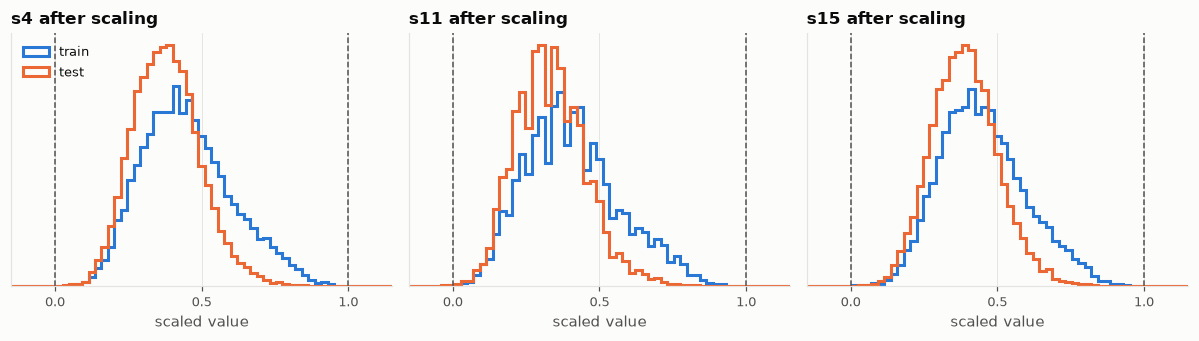

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=False)
for ax, s in zip(axes, ["s4", "s11", "s15"]):
    bins = np.linspace(-0.15, 1.15, 60)
    ax.hist(d.train[s], bins=bins, density=True, histtype="step", lw=2, color=BLUE, label="train")
    ax.hist(d.test[s], bins=bins, density=True, histtype="step", lw=2, color=ORANGE, label="test")
    for x in (0, 1): ax.axvline(x, color=TEXT_SECONDARY, lw=1, ls="--")
    ax.set(title=f"{s} after scaling", xlabel="scaled value", xlim=(-0.15, 1.15), xticks=[0, 0.5, 1]); ax.set_yticks([])
    print(f"{s}: train [{d.train[s].min():.3f}, {d.train[s].max():.3f}]   test [{d.test[s].min():.3f}, {d.test[s].max():.3f}]")
axes[0].legend(loc="upper left")
fig.tight_layout(); save_fig(fig, "fe_scaling"); plt.show()

## 2 · What rolling, lag and EMA features look like
> **How to read this figure:** one engine's life, left = new, right = failure. Top panel: the scaled raw sensor s11
> (thin, noisy) with two smoothed versions drawn over it. Bottom panel: the *rolling standard deviation* — how much
> the sensor jumped around during the last 10 cycles.

**What it tells us:**
- the raw reading is noisy; the **rolling mean** and **EMA** remove the noise and expose the trend — the EMA reacts
  a little faster because it weights recent cycles more;
- the **rolling std stays roughly flat** (≈ 0.05–0.10) over this engine's whole life. The original plan expected it
  to rise toward failure ("instability grows"); **in FD001 that does not happen** — the sensor's *level* drifts, its
  noise does not grow. Section 3 confirms it across all engines: rolling std is the weakest feature family.
  The features stay in the set (no evidence-free pruning); SHAP will show whether XGBoost finds any use for them.

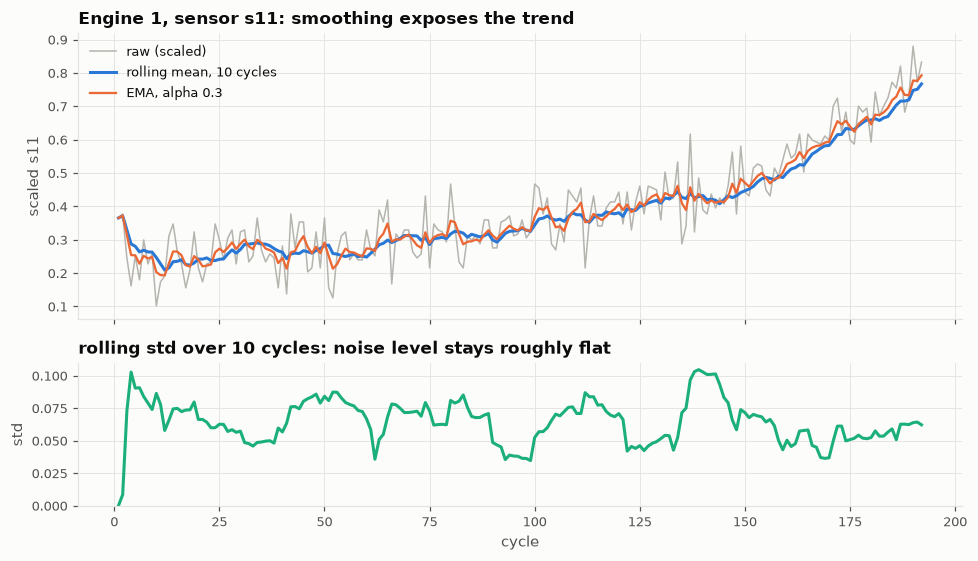

In [3]:
f_train = build_tabular_features(d.train)
eng = d.train_units[0]
e = f_train[f_train.unit_id == eng]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
a1.plot(e.cycle, e.s11, color=MUTED, lw=1, label="raw (scaled)")
a1.plot(e.cycle, e.s11_rollmean_10, color=BLUE, label="rolling mean, 10 cycles")
a1.plot(e.cycle, e.s11_ema, color=ORANGE, lw=1.5, label="EMA, alpha 0.3")
a1.set(title=f"Engine {eng}, sensor s11: smoothing exposes the trend", ylabel="scaled s11"); a1.legend(loc="upper left")
a2.plot(e.cycle, e.s11_rollstd_10, color=AQUA)
a2.set(title="rolling std over 10 cycles: noise level stays roughly flat", xlabel="cycle", ylabel="std", ylim=(0, None))
fig.tight_layout(); save_fig(fig, "fe_s11_rolling"); plt.show()

## 3 · Which feature families carry the most signal?
> **How to read this figure:** each bar is one of the 238 features (the 25 strongest shown). Bar length = how strongly
> the feature tracks RUL (|Spearman correlation|, 0 = unrelated, 1 = perfect ranking). Colour = feature family.

**What it tells us:** smoothed features (rolling means, EMA) beat raw readings — averaging cancels sensor noise.
The printed table below shows the strongest feature of each family: rolling mean / EMA ≈ 0.76 > raw ≈ 0.72 >
rolling std ≈ 0.47 (weakest, see section 2). This is a *univariate* view (one feature at a time); XGBoost combines features, and SHAP (later) will
show what it actually relies on. Correlation is a sanity check here, not a feature-selection step — all 238 are kept.

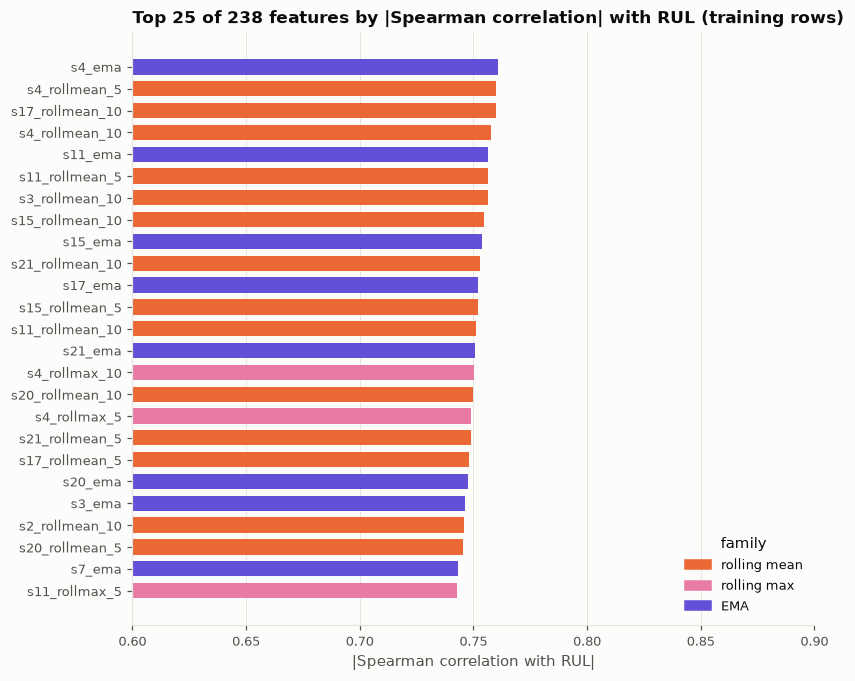

strongest feature per family:
raw             0.723
rolling mean    0.760
rolling std     0.466
rolling min     0.741
rolling max     0.750
lag             0.717
EMA             0.761


In [4]:
names = tabular_feature_names()
corr = f_train[names].corrwith(f_train.rul, method="spearman").abs().sort_values(ascending=False)
def family(n):
    if "_roll" in n: return "rolling " + n.split("_roll")[1].split("_")[0]
    if "_lag_" in n: return "lag"
    if n.endswith("_ema"): return "EMA"
    return "raw"
fams = ["raw", "rolling mean", "rolling std", "rolling min", "rolling max", "lag", "EMA"]
col = dict(zip(fams, CATEGORICAL))
top = corr.head(25)[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top.index, top.values, color=[col[family(n)] for n in top.index], height=0.7)
handles = [plt.Rectangle((0, 0), 1, 1, color=col[f]) for f in fams if f in {family(n) for n in top.index}]
ax.legend(handles, [f for f in fams if f in {family(n) for n in top.index}], loc="lower right", title="family")
ax.set(title="Top 25 of 238 features by |Spearman correlation| with RUL (training rows)",
       xlabel="|Spearman correlation with RUL|", xlim=(0.6, 0.9)); ax.grid(axis="y", visible=False)
save_fig(fig, "fe_top_features"); plt.show()
best = corr.groupby(corr.index.map(family)).max().reindex(fams)
print("strongest feature per family:"); print(best.round(3).to_string())

## 4 · What a sequence model sees: one 30-cycle window
> **How to read this figure:** each panel is one input window — 30 cycles (left → right, oldest → newest) × 14
> sensors (rows). Colour = scaled value (light = low, dark = high). Left: a window from a healthy engine; right: the
> same engine's last window before failure.

**What it tells us:** compare the two panels row by row. Near failure the *level* of most sensors has moved —
s2, s3, s4, s11, s15 are darker (higher), s7, s12, s20, s21 lighter (lower) — the same directions as the EDA trends.
Within one 30-cycle window the change is small; the model mostly reads *where each sensor sits* plus its short-term slope. TCN, LSTMs and ROCKET receive exactly this 30 × 14 picture and
must learn to read it — no hand-made features.

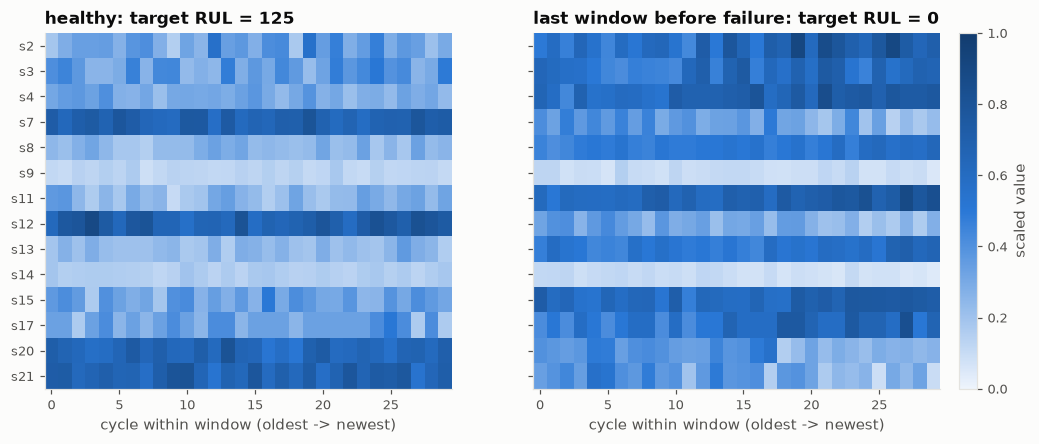

sequence tensors: (14070, 30, 14) (windows, cycles, sensors)


In [5]:
X, y, u = generate_sequences(d.train)
idx = np.where(u == eng)[0]
healthy, failing = idx[0], idx[-1]
seq_cmap = LinearSegmentedColormap.from_list("seq_blue", ["#eef4fc", BLUE, "#123c6e"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, i, t in [(axes[0], healthy, "healthy"), (axes[1], failing, "last window before failure")]:
    im = ax.imshow(X[i].T, aspect="auto", cmap=seq_cmap, vmin=0, vmax=1)
    ax.set(title=f"{t}: target RUL = {y[i]:.0f}", xlabel="cycle within window (oldest -> newest)")
    ax.set_yticks(range(14), config.SENSORS); ax.grid(False)
fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02, label="scaled value")
save_fig(fig, "fe_window_example"); plt.show()
print("sequence tensors:", X.shape, "(windows, cycles, sensors)")

## 5 · Test inputs: one per engine
Each test engine contributes exactly **one** input: its last 30 cycles (sequences) or its last row (tabular).
Shapes must line up with the 100 ground-truth values in `RUL_FD001.txt`.

In [6]:
X_test, units = last_window_per_engine(d.test)
f_test_last = build_tabular_features(d.test).groupby("unit_id").tail(1)
print("test windows:", X_test.shape, "| test tabular rows:", f_test_last.shape, "| truth values:", len(d.test_truth))
assert len(units) == len(f_test_last) == len(d.test_truth) == 100

test windows: (100, 30, 14) | test tabular rows: (100, 240) | truth values: 100


## Takeaways
1. **Split by engine, scaler fit on training engines only** — validated by tests that fail if either rule is broken
   (`tests/test_feature_pipeline.py`, checked by deliberately breaking the code).
2. **All features look backwards only**; a test changes future cycles and asserts earlier features are unchanged.
3. **Features need only the last 30 cycles** (no absolute `cycle` feature) — so the API, which receives a recent window
   of readings, computes exactly what training computed (tested).
4. Smoothed features (rolling mean / EMA) carry more signal than raw readings; rolling std captures growing instability.
5. Two model inputs: **238 tabular features** for XGBoost, **30 × 14 windows** for TCN / LSTMs / ROCKET.